In [3]:
import pandas as pd
import numpy as np
from pathlib import Path

DATA_DIR = Path('../data/raw/mimic-iv-demo')

# Load core tables
icustays = pd.read_csv(DATA_DIR / 'icu/icustays.csv.gz')
chartevents = pd.read_csv(DATA_DIR / 'icu/chartevents.csv.gz')
labevents = pd.read_csv(DATA_DIR / 'hosp/labevents.csv.gz')
patients = pd.read_csv(DATA_DIR / 'hosp/patients.csv.gz')
admissions = pd.read_csv(DATA_DIR / 'hosp/admissions.csv.gz')

print("=== TABLE SHAPES ===")

for name, df in [
    ('icustays', icustays),
    ('chartevents', chartevents),
    ('labevents', labevents),
    ('patients', patients),
    ('admissions', admissions)
]:
    print(f"{name:15s}: {df.shape[0]:>8,} rows × {df.shape[1]:>3} cols")

print("\n=== ICU STAYS ===")
print(f"Unique patients: {icustays['subject_id'].nunique()}")
print(f"Unique stays: {icustays['stay_id'].nunique()}")

print(f"\nColumns: {icustays.columns.tolist()}")
print(icustays.head(3))

=== TABLE SHAPES ===
icustays       :      140 rows ×   8 cols
chartevents    :  668,862 rows ×  11 cols
labevents      :  107,727 rows ×  16 cols
patients       :      100 rows ×   6 cols
admissions     :      275 rows ×  16 cols

=== ICU STAYS ===
Unique patients: 100
Unique stays: 140

Columns: ['subject_id', 'hadm_id', 'stay_id', 'first_careunit', 'last_careunit', 'intime', 'outtime', 'los']
   subject_id   hadm_id   stay_id  \
0    10018328  23786647  31269608   
1    10020187  24104168  37509585   
2    10020187  26842957  32554129   

                                    first_careunit       last_careunit  \
0                                   Neuro Stepdown      Neuro Stepdown   
1  Neuro Surgical Intensive Care Unit (Neuro SICU)      Neuro Stepdown   
2                               Neuro Intermediate  Neuro Intermediate   

                intime              outtime       los  
0  2154-04-24 23:03:44  2154-05-02 15:55:21  7.702512  
1  2169-01-15 04:56:00  2169-01-20 15:47:50

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from pathlib import Path

DATA_DIR = Path('../data/raw/mimic-iv-demo')

icustays = pd.read_csv(DATA_DIR / 'icu/icustays.csv.gz')
chartevents = pd.read_csv(DATA_DIR / 'icu/chartevents.csv.gz')
labevents = pd.read_csv(DATA_DIR / 'hosp/labevents.csv.gz')
patients = pd.read_csv(DATA_DIR / 'hosp/patients.csv.gz')
admissions = pd.read_csv(DATA_DIR / 'hosp/admissions.csv.gz')

print("=== TABLE SIZES ===")
for name, df in [('icustays',icustays),('chartevents',chartevents),
                 ('labevents',labevents),('patients',patients),
                 ('admissions',admissions)]:
    print(f"  {name:15s}: {len(df):>8,} rows × {df.shape[1]} cols")

print(f"\nUnique ICU stays : {icustays['stay_id'].nunique()}")
print(f"Unique patients  : {icustays['subject_id'].nunique()}")

=== TABLE SIZES ===
  icustays       :      140 rows × 8 cols
  chartevents    :  668,862 rows × 11 cols
  labevents      :  107,727 rows × 16 cols
  patients       :      100 rows × 6 cols
  admissions     :      275 rows × 16 cols

Unique ICU stays : 140
Unique patients  : 100


In [3]:
VITAL_IDS = {220210:'resp_rate', 220277:'spo2',
             220045:'heart_rate', 220179:'systolic_bp', 223762:'temperature'}
LAB_IDS   = {50813:'lactate', 50912:'creatinine', 51301:'wbc'}

vitals = chartevents[chartevents['itemid'].isin(VITAL_IDS)].copy()
vitals['feature'] = vitals['itemid'].map(VITAL_IDS)
vitals = vitals.dropna(subset=['valuenum'])

labs = labevents[labevents['itemid'].isin(LAB_IDS)].copy()
labs['feature'] = labs['itemid'].map(LAB_IDS)
labs = labs.dropna(subset=['valuenum'])

print("=== VITAL SIGN COVERAGE ===")
n_stays = icustays['stay_id'].nunique()
for feat, grp in vitals.groupby('feature'):
    n = grp['stay_id'].nunique()
    print(f"  {feat:15s}: {n:3}/{n_stays} stays | "
          f"range [{grp['valuenum'].min():.1f}, {grp['valuenum'].max():.1f}]")

print("\n=== LAB VALUE COVERAGE ===")
for feat, grp in labs.groupby('feature'):
    n = grp['subject_id'].nunique()
    print(f"  {feat:15s}: {n:3} patients | "
          f"range [{grp['valuenum'].min():.1f}, {grp['valuenum'].max():.1f}]")

=== VITAL SIGN COVERAGE ===
  heart_rate     : 140/140 stays | range [0.0, 200.0]
  resp_rate      : 140/140 stays | range [0.0, 58.0]
  spo2           : 140/140 stays | range [29.0, 100.0]
  systolic_bp    : 139/140 stays | range [46.0, 215.0]
  temperature    :  15/140 stays | range [31.1, 99.0]

=== LAB VALUE COVERAGE ===
  creatinine     : 100 patients | range [0.1, 15.2]
  lactate        :  83 patients | range [0.5, 13.2]
  wbc            : 100 patients | range [0.1, 182.6]


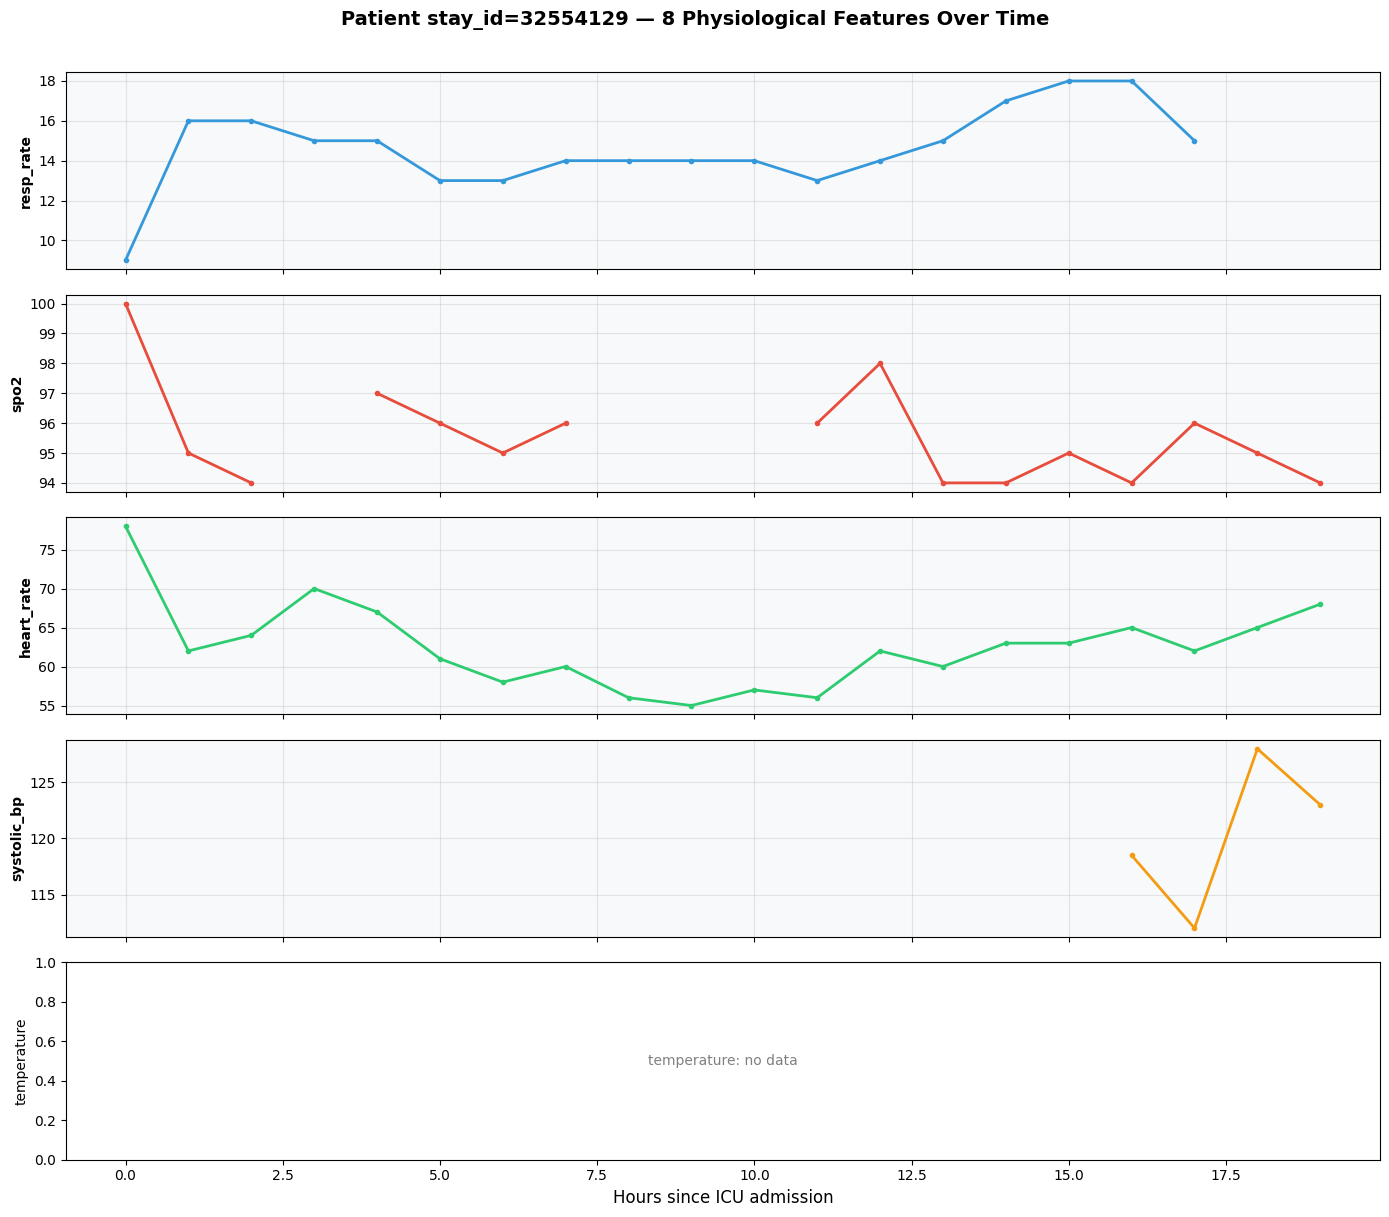

Saved: results/figures/patient_timeline.png


In [5]:
# Pick a patient with good data coverage
stay_id = icustays['stay_id'].iloc[2]
intime  = pd.to_datetime(
    icustays.loc[icustays['stay_id']==stay_id,'intime'].values[0])

pt = vitals[vitals['stay_id']==stay_id].copy()
pt['charttime'] = pd.to_datetime(pt['charttime'])
pt['hour'] = ((pt['charttime']-intime)
              .dt.total_seconds()/3600).round().astype(int)
pt = pt[pt['hour'] >= 0]

pt_wide = pt.pivot_table(index='hour', columns='feature',
                          values='valuenum', aggfunc='mean')

# Plot
fig, axes = plt.subplots(5, 1, figsize=(14, 12), sharex=True)
colors = ['#3498db','#e74c3c','#2ecc71','#f39c12','#9b59b6']
for ax, (feat, col) in zip(axes, zip(VITAL_IDS.values(), colors)):
    if feat in pt_wide.columns:
        ax.plot(pt_wide.index, pt_wide[feat],
                color=col, linewidth=2, marker='o', markersize=3)
        ax.set_ylabel(feat, fontsize=10, fontweight='bold')
        ax.grid(True, alpha=0.3)
        ax.set_facecolor('#f8f9fa')
    else:
        ax.text(0.5, 0.5, f'{feat}: no data', ha='center', va='center',
                transform=ax.transAxes, color='gray')
        ax.set_ylabel(feat, fontsize=10)

axes[-1].set_xlabel('Hours since ICU admission', fontsize=12)
plt.suptitle(f'Patient stay_id={stay_id} — 8 Physiological Features Over Time',
             y=1.01, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../results/figures/patient_timeline.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: results/figures/patient_timeline.png")